# Lab 6 — Data Visualization & EDA: Look Before You Model
**ARTI 303 — Programming for AI**

**Name:** _[your name]_  **Student ID:** _[your ID]_  **Section:** _[your section]_

---

### What this lab is really about

Last lab you made the data trustworthy. This lab is about what comes
next: **look at it**.

Exploratory data analysis (EDA) means getting to know a dataset with a
few charts and a few well-chosen numbers before anyone builds anything
on top of it. It's where you find the surprises: the skewed column, the
group that is tiny, the relationship that isn't really there.

This lab has **five ideas**. Each one is short: a few minutes of
explanation, then an exercise that checks itself.

| Part | Idea | You will be able to |
|---|---|---|
| 1 | Choose the chart for the question | pick a chart type, and spot a misleading one |
| 2 | Matplotlib essentials | build a labelled figure and save it |
| 3 | Seaborn | compare groups in a single line |
| 4 | Statistical plots | read a distribution and find outliers |
| 5 | Correlation | measure a relationship, and know when not to trust it |

After Part 5 there is a short AI checkpoint, and a list of resources if
you want to go further.

---

## Setup

Same course folder, same environment as before:

```
arti303_lab/
├── .venv/
├── requirements.txt
├── lab06.ipynb        <- this lab
├── data/
└── ...
```

**1.** Open `arti303_lab` in VS Code (`File → Open Folder`) — the folder
itself, not a lab file inside it.

**2.** Get the environment ready, in this order:

- Look for a `.venv` folder in the file list. If it isn't there, create
  it once: `python -m venv .venv`
- Activate it:

```bash
source .venv/bin/activate          # macOS / Linux / Git Bash
.venv\Scripts\Activate.ps1         # Windows PowerShell
```

- Check your prompt starts with `(.venv)`. If it shows `(base)`, you're
  in Anaconda's environment and packages will install to the wrong place.

**3.** Install today's two libraries and record them:

```bash
python -m pip install matplotlib seaborn
python -m pip freeze > requirements.txt
```

**4.** Point this notebook at the same environment:
`Cmd+Shift+P` (macOS) / `Ctrl+Shift+P` (Windows) → **Python: Select
Interpreter** → the entry showing `.venv`. Then restart the kernel.

### Check your setup

In [34]:
import os
import sys

problems = []

if sys.prefix != sys.base_prefix:
    print("[ok]   Running inside a virtual environment")
else:
    print("[!]    NOT in a virtual environment")
    problems.append("Select the .venv interpreter, then restart the kernel")
print("       using:", sys.executable)
print()

for name in ["pandas", "numpy", "matplotlib", "seaborn"]:
    try:
        module = __import__(name)
        print(f"[ok]   {name} {module.__version__}")
    except ImportError:
        print(f"[!]    {name} is not installed in this environment")
        problems.append(f"Run: python -m pip install {name}")

if os.path.exists("../requirements.txt"):
    lines = [l.lower() for l in open("../requirements.txt").read().splitlines() if l.strip()]
    for name in ["matplotlib", "seaborn"]:
        if any(name in l for l in lines):
            print(f"[ok]   {name} is recorded in requirements.txt")
        else:
            print(f"[!]    {name} is missing from requirements.txt")
            problems.append("Run: python -m pip freeze > requirements.txt")
    if len(lines) > 100:
        print("[!]    requirements.txt has", len(lines), "packages - that looks like Anaconda's base")
        problems.append("Delete it, activate .venv, freeze again")
else:
    print("[!]    No requirements.txt found")
    problems.append("Run: python -m pip freeze > requirements.txt")

print()
print("Fix these first:" if problems else "Setup looks good.")
for item in problems:
    print("  -", item)

[ok]   Running inside a virtual environment
       using: c:\Users\hebaa\Desktop\arti303-2259177-alkatheri\.venv\Scripts\python.exe

[ok]   pandas 3.0.6
[ok]   numpy 2.5.3
[ok]   matplotlib 3.11.2
[ok]   seaborn 0.13.2
[ok]   matplotlib is recorded in requirements.txt
[ok]   seaborn is recorded in requirements.txt

Setup looks good.


---
### The data

Today's dataset describes 150 students: their department, weekly study
hours, attendance, daily phone hours, and GPA.

It is **synthetic**: the code below generates it with a fixed seed, so
everyone gets exactly the same file. It is not real IAU data, but the
departments are real (`CE` Computer Engineering, `CS` Computer Science,
`BME` Biomedical Engineering).

Run both cells.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../data", exist_ok=True)

# Generate the dataset (you don't need to understand this cell)
rng = np.random.default_rng(303)
n = 150
dept = rng.choice(["CE", "CS", "BME"], size=n, p=[0.40, 0.37, 0.23])
study_hours = np.clip(rng.normal(14, 5, n), 2, 38).round(1)
attendance = np.clip(68 + 1.1 * study_hours + rng.normal(0, 6, n), 40, 100).round(0)
phone_hours = np.clip(rng.normal(4.5, 1.6, n) - 0.05 * (study_hours - 14), 0.5, 10).round(1)
gpa = np.clip(
    2.0 + 0.075 * study_hours + 0.012 * (attendance - 80) - 0.05 * (phone_hours - 4.5)
    + rng.normal(0, 0.35, n),
    1.0, 5.0,
).round(2)

pd.DataFrame({
    "student_id": np.arange(2001, 2001 + n),
    "dept": dept,
    "study_hours": study_hours,
    "attendance": attendance,
    "phone_hours": phone_hours,
    "gpa": gpa,
}).to_csv("../data/students_eda.csv", index=False)

df = pd.read_csv("../data/students_eda.csv")
print("shape:", df.shape)
df.head()

shape: (150, 6)


,student_id,dept,study_hours,attendance,phone_hours,gpa
0,2001,CE,13.6,83.0,6.2,3.14
1,2002,CS,17.1,90.0,4.4,3.96
2,2003,BME,16.8,81.0,4.8,3.77
3,2004,CE,12.5,77.0,3.1,2.65
4,2005,BME,13.4,97.0,2.8,3.10


In [36]:
df.describe().round(2)

,student_id,study_hours,attendance,phone_hours,gpa
count,150.00,150.00,150.00,150.00,150.00
mean,2075.50,13.79,83.42,4.57,3.07
std,43.45,5.12,7.57,1.51,0.57
min,2001.00,2.00,64.00,0.60,1.63
25%,2038.25,10.52,79.00,3.70,2.68
50%,2075.50,13.40,83.00,4.60,3.05
75%,2112.75,16.95,88.75,5.50,3.43
max,2150.00,29.90,100.00,8.50,4.70


---
# Part 1 · Choose the chart for the question

Every chart answers a question. If you pick the chart first and the
question second, you usually get a pretty picture that answers nothing.

| Your question | Chart |
|---|---|
| How is one numeric column spread out? | histogram (or box plot) |
| How do groups compare? | bar chart (the average) or box plot (the spread) |
| Are two numeric columns related? | scatter plot |
| How does something change over time or order? | line chart |

### Three rules for an honest chart

1. **One question, one chart.**
2. **Label everything**: a title, both axis labels, units.
3. **Don't distort.** A bar chart's axis must start at zero.

Rule 3 is the one that gets broken most often, usually without anyone
meaning to. Here is the same data twice:

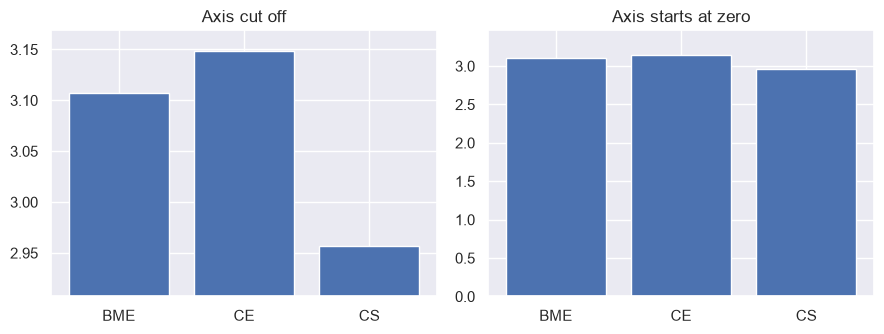

In [37]:
#axis by default starts at zero
means = df.groupby("dept")["gpa"].mean()

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.5))

left.bar(means.index, means.values)
left.set_ylim(means.min() - 0.05, means.max() + 0.02)
left.set_title("Axis cut off")

right.bar(means.index, means.values)

right.set_ylim(0, means.max() * 1.1)
right.set_title("Axis starts at zero")

fig.tight_layout()

Same numbers. The left chart makes one department look far better than
another; the right chart shows that the averages are close. Neither chart
contains a false number — the first one just *feels* false.

> Whenever you see a bar chart, look at where the axis starts before you
> look at the bars.

### Exercise 1.1
Match each question to the best chart. Choose from:
`"histogram"`, `"bar"`, `"scatter"`, `"line"`.

In [38]:
chart_for = {
    "How is study_hours spread across all students?": "histogram",
    "Which department has the highest average GPA?": "bar",
    "Is attendance related to GPA?": "scatter",
    "How did average GPA change from one semester to the next?": 'line',
}

In [39]:
expected = ["histogram", "bar", "scatter", "line"]
answers = list(chart_for.values())
assert None not in answers, "fill in all four answers"
for (question, given), right in zip(chart_for.items(), expected):
    assert given == right, f"'{question}' -> not '{given}'. Re-read the table above."
print("Exercise 1.1 correct.")

Exercise 1.1 correct.


---
# Part 2 · Matplotlib essentials

Matplotlib is the library underneath almost every plot in Python.

**Two objects matter:**

- a **Figure** is the whole canvas
- an **Axes** is one plot on it

You create both in one line, then call methods on the Axes:

```python
fig, ax = plt.subplots()
```

Use this style every time. It keeps working when you want two or three
plots side by side, and it is what you will see in other people's code.

Text(0, 0.5, 'Average GPA')

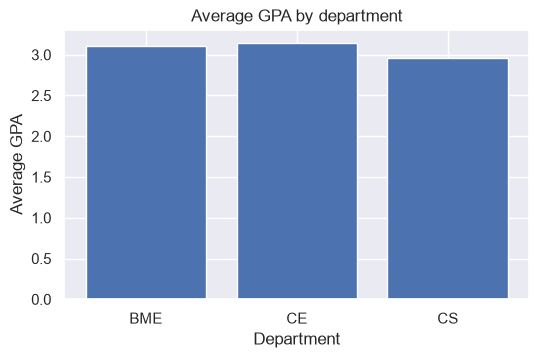

In [40]:
fig, ax = plt.subplots(figsize=(6, 3.5))

ax.bar(means.index, means.values)
ax.set_title("Average GPA by department")
ax.set_xlabel("Department")
ax.set_ylabel("Average GPA")

The four methods you will use most:

| Method | Draws |
|---|---|
| `ax.bar(x, heights)` | bars |
| `ax.hist(values, bins=...)` | a histogram |
| `ax.scatter(x, y)` | one dot per row |
| `ax.plot(x, y)` | a line |

Several plots on one figure is just a bigger grid of Axes:

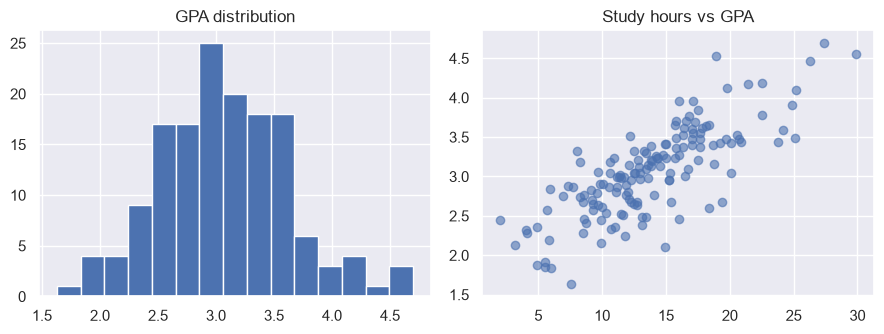

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))

ax1.hist(df["gpa"], bins=15)
ax1.set_title("GPA distribution")

ax2.scatter(df["study_hours"], df["gpa"], alpha=0.6)
ax2.set_title("Study hours vs GPA")

fig.tight_layout()

`alpha=0.6` makes dots slightly transparent, so overlapping points show
up darker. Useful whenever you have more than a few dozen points.

### Exercise 2.1
Draw a scatter plot of `attendance` (x axis) against `gpa` (y axis) on
the `ax` below, with a title and both axis labels.

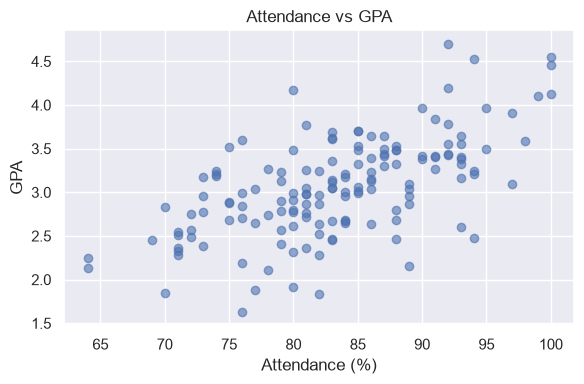

In [42]:
fig, ax = plt.subplots(figsize=(6, 4))

# TODO: scatter attendance (x) against gpa (y), then add a title and both axis labels
ax.scatter(df["attendance"], df["gpa"], alpha=0.6)
ax.set_title("Attendance vs GPA")
ax.set_xlabel("Attendance (%)")
ax.set_ylabel("GPA")
fig.tight_layout()

In [43]:
assert len(ax.collections) == 1, "draw one scatter plot with ax.scatter(...)"
assert len(ax.collections[0].get_offsets()) == len(df), "plot every student - pass the full columns"
assert np.allclose(ax.collections[0].get_offsets()[:, 0], df["attendance"]), \
    "attendance should be on the x axis, gpa on the y axis"
assert ax.get_title(), "add a title with ax.set_title(...)"
assert ax.get_xlabel() and ax.get_ylabel(), "label both axes with ax.set_xlabel / ax.set_ylabel"
print("Exercise 2.1 correct.")

Exercise 2.1 correct.


### Exercise 2.2
A chart you can't share is only half useful. Save the figure from 2.1 as
`figures/attendance_vs_gpa.png`.

Two things to know: `fig.savefig(path)` does the saving, and the
`figures` folder must exist first (`os.makedirs("figures", exist_ok=True)`).
Add `dpi=150, bbox_inches="tight"` for a sharp image with nothing cut off.

In [44]:
# TODO: create the figures folder, then save fig into it
os.makedirs("../figures", exist_ok=True)
fig.savefig("../figures/attendance_vs_gpa.png", dpi=150, bbox_inches="tight")

In [45]:
assert os.path.exists("../figures/attendance_vs_gpa.png"), \
    "../figures/attendance_vs_gpa.png not found - did you create the folder and call fig.savefig?"
assert os.path.getsize("../figures/attendance_vs_gpa.png") > 1000, "the file looks empty"
print("Exercise 2.2 correct.")

Exercise 2.2 correct.


---
# Part 3 · Seaborn: compare groups in one line

Seaborn is built on Matplotlib and understands DataFrames. You say
*which columns*; it does the grouping and averaging for you.

Compare with Part 2, where you computed `means` yourself first:

```python
sns.barplot(data=df, x="dept", y="gpa", ax=ax)
```

Three charts that answer three different questions about groups:

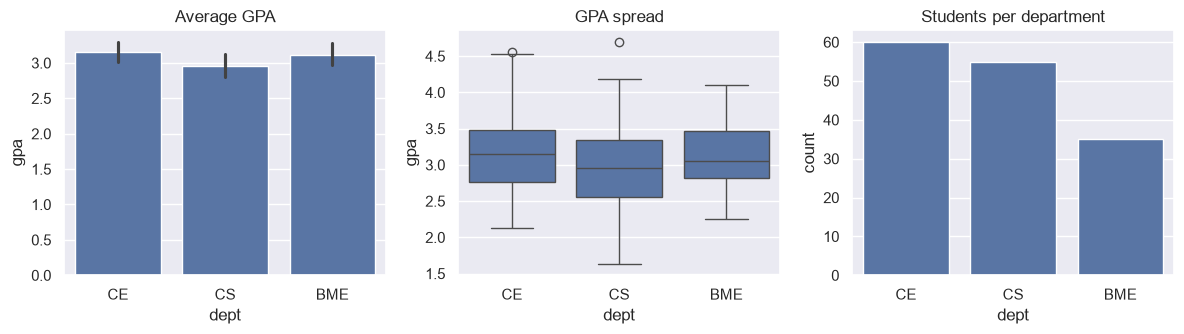

In [46]:
sns.set_style()
sns.set_theme()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

sns.barplot(data=df, x="dept", y="gpa", ax=axes[0])
axes[0].set_title("Average GPA")

sns.boxplot(data=df, x="dept", y="gpa", ax=axes[1])
axes[1].set_title("GPA spread")

sns.countplot(data=df, x="dept", ax=axes[2])
axes[2].set_title("Students per department")

fig.tight_layout()

Read them together:

- **Bar plot**: the average. The thin black line on each bar is a
  **confidence interval**: how sure we are about that average. If two
  bars' lines overlap a lot, the difference between those groups may not
  be real.
- **Box plot**: the spread (Part 4 explains how to read one).
- **Count plot**: how many students are in each group. Always check this
  before trusting an average. An average of 5 students is not the same
  as an average of 60.

Every Seaborn function takes `ax=`, so you can put it on the Axes you
created in Part 2 and still use `set_title`, `set_xlabel` and the rest.

### Exercise 3.1
Draw a box plot of `study_hours` for each department on the `ax` below.

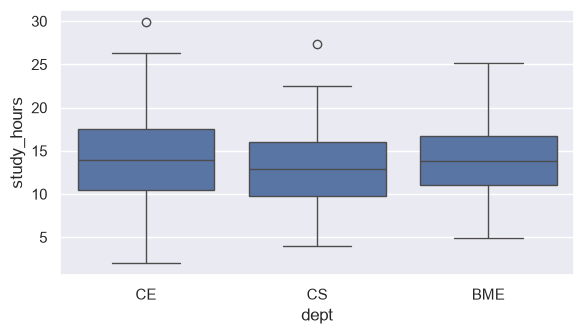

In [47]:
fig, ax = plt.subplots(figsize=(6, 3.5))

# TODO: box plot of study_hours for each department, drawn on ax
sns.boxplot(data=df, x="dept", y="study_hours", ax=ax)
fig.tight_layout()

In [48]:
assert len(ax.patches) == 3, "expected three boxes, one per department - use sns.boxplot(..., ax=ax)"
assert {t.get_text() for t in ax.get_xticklabels()} == set(df["dept"]), "x axis should be dept"
assert ax.get_ylabel() == "study_hours", "y axis should be study_hours"
print("Exercise 3.1 correct.")

Exercise 3.1 correct.


### Exercise 3.2
Look at the GPA box plot above: one department's box is taller than the
others, meaning its GPAs are more spread out. Confirm it with a number.

Store the name of the department with the **largest standard deviation
of `gpa`** in `widest_gpa_spread` (a string).

In [49]:
widest_gpa_spread = "CS"


In [50]:
assert widest_gpa_spread is not None, "fill in widest_gpa_spread"
expected = df.groupby("dept")["gpa"].std().idxmax()
assert widest_gpa_spread == expected, \
    f"not '{widest_gpa_spread}' - compute df.groupby('dept')['gpa'].std() and pick the largest"
print("Exercise 3.2 correct.")

Exercise 3.2 correct.


---
# Part 4 · Statistical plots: the average hides the shape

An average is one number. Two very different groups can share it:

average of A: 2.95
average of B: 3.0


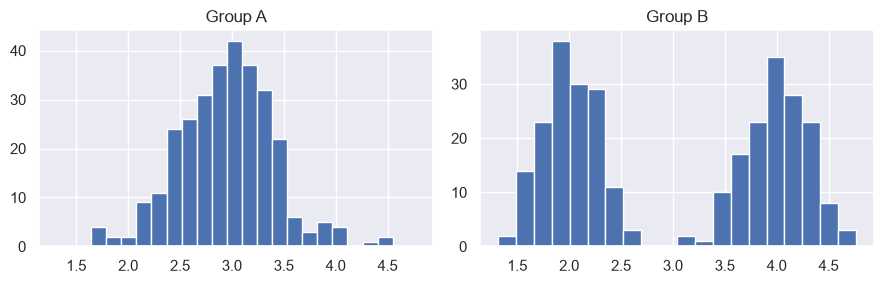

In [51]:
demo_rng = np.random.default_rng(1)
group_a = demo_rng.normal(3.0, 0.5, 300)
group_b = np.concatenate([demo_rng.normal(2.0, 0.3, 150), demo_rng.normal(4.0, 0.3, 150)])

print("average of A:", round(group_a.mean(), 2))
print("average of B:", round(group_b.mean(), 2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
ax1.hist(group_a, bins=20)
ax1.set_title("Group A")
ax2.hist(group_b, bins=20)
ax2.set_title("Group B")
fig.tight_layout()

Same average. Group A is one cluster; Group B is two clusters with
nobody near the average at all. If you had only looked at the mean, you
would never know.

### Histogram and KDE

A **histogram** counts how many values fall in each bin. Adding
`kde=True` draws a smooth curve over it (a *kernel density estimate*),
which makes the overall shape easier to see.

Text(0.5, 1.0, 'GPA distribution')

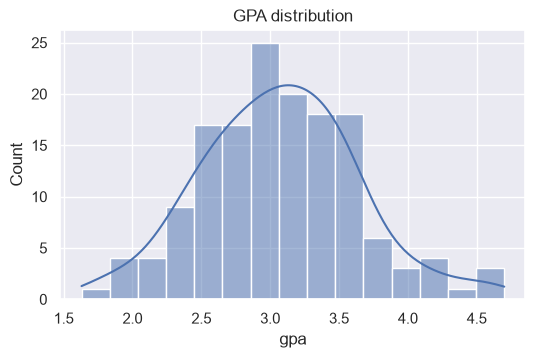

In [52]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(data=df, x="gpa", bins=15, kde=True, ax=ax)
ax.set_title("GPA distribution")

### Box plot

A box plot squeezes a distribution into five facts:

| Part of the plot | Meaning |
|---|---|
| line inside the box | the **median** (the middle value) |
| the box | the middle 50% of values (Q1 to Q3); its height is the **IQR** |
| whiskers | the range of ordinary values |
| dots beyond the whiskers | **outliers** |

The standard rule: a value is an outlier if it is more than **1.5 × IQR**
below Q1 or above Q3.

In [53]:
q1, q3 = df["study_hours"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"ordinary range: {low:.2f} to {high:.2f}")

outliers = df[(df["study_hours"] < low) | (df["study_hours"] > high)]
outliers

Q1 = 10.525, Q3 = 16.95, IQR = 6.424999999999999
ordinary range: 0.89 to 26.59


,student_id,dept,study_hours,attendance,phone_hours,gpa
11,2012,CE,29.9,100.0,1.5,4.55
84,2085,CS,27.4,92.0,2.8,4.70


> An outlier is a **question**, not an error. It might be a typing
> mistake, or it might be your most interesting student. Find out which
> before you delete anything.

### Exercise 4.1
Apply the same rule to `phone_hours`. Store the number of outliers in
`n_phone_outliers`.

In [54]:
q1, q3 = df["phone_hours"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"ordinary range: {low:.2f} to {high:.2f}")

n_phone_outliers = int(((df["phone_hours"] < low) | (df["phone_hours"] > high)).sum())

n_phone_outliers 


Q1 = 3.7, Q3 = 5.5, IQR = 1.7999999999999998
ordinary range: 1.00 to 8.20


4

In [55]:
assert n_phone_outliers is not None, "fill in n_phone_outliers"
q1, q3 = df["phone_hours"].quantile([0.25, 0.75])
low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
expected = int(((df["phone_hours"] < low) | (df["phone_hours"] > high)).sum())
assert n_phone_outliers == expected, \
    f"expected {expected}, got {n_phone_outliers} - count values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR"
print("Exercise 4.1 correct.")

Exercise 4.1 correct.


### Exercise 4.2
Draw a histogram of `study_hours` with **12 bins**, a title, and an x
axis label, on the `ax` below.

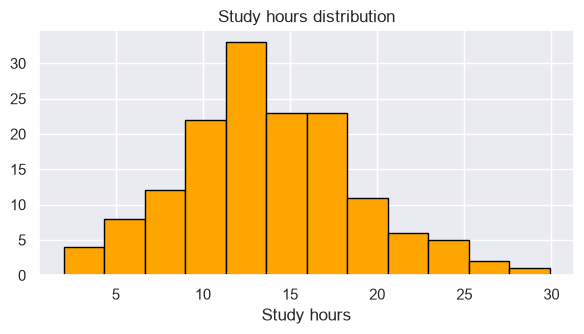

In [56]:
fig, ax = plt.subplots(figsize=(6, 3.5))

# TODO: histogram of study_hours with 12 bins, plus a title and an x label
ax.hist(df["study_hours"], bins=12, color='orange', edgecolor='black')
ax.set_title("Study hours distribution")
ax.set_xlabel("Study hours")
fig.tight_layout()


In [57]:
assert len(ax.patches) == 12, f"expected 12 bars (bins=12), found {len(ax.patches)}"
assert ax.get_title(), "add a title"
assert ax.get_xlabel(), "add an x label"
print("Exercise 4.2 correct.")

Exercise 4.2 correct.


---
# Part 5 · Correlation: measuring a relationship

The **correlation coefficient** `r` measures how closely two numeric
columns move together, on a scale from −1 to +1:

| `r` | Meaning |
|---|---|
| near +1 | when one goes up, the other goes up |
| near 0 | no straight-line relationship |
| near −1 | when one goes up, the other goes down |

As a rough guide, below 0.3 is weak, 0.3 to 0.7 moderate, above 0.7
strong. `df.corr()` computes it for every pair of numeric columns.

One thing first: `student_id` is a number, but it means nothing as a
number. Drop it before correlating.

In [58]:
corr = df.drop(columns="student_id").corr(numeric_only=True)
corr2 = df.drop(columns="student_id").corr(numeric_only=True, method="spearman")
print(corr.round(2))
print()
print(corr2.round(2))

             study_hours  attendance  phone_hours   gpa
study_hours         1.00        0.70        -0.12  0.79
attendance          0.70        1.00        -0.12  0.62
phone_hours        -0.12       -0.12         1.00 -0.18
gpa                 0.79        0.62        -0.18  1.00

             study_hours  attendance  phone_hours   gpa
study_hours         1.00        0.67        -0.13  0.78
attendance          0.67        1.00        -0.10  0.60
phone_hours        -0.13       -0.10         1.00 -0.17
gpa                 0.78        0.60        -0.17  1.00


A **heatmap** turns that table into colour. `vmin=-1, vmax=1` fixes the
scale, so the same colour always means the same thing.

Text(0.5, 1.0, 'Correlation between columns')

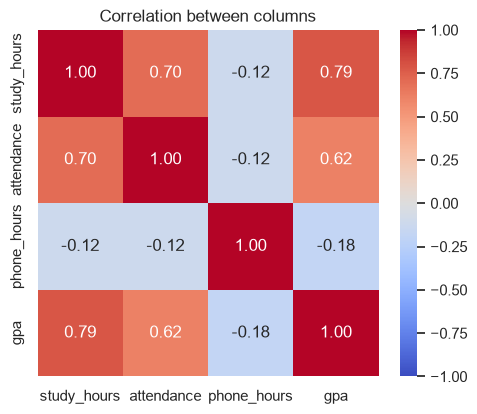

In [59]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between columns")

To see what a correlation looks like, plot the pair. `regplot` adds the
best-fit straight line:

Text(0.5, 1.0, 'Study hours vs GPA')

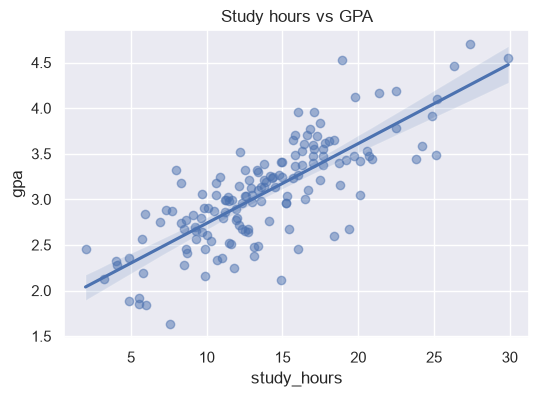

In [60]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.regplot(data=df, x="study_hours", y="gpa", scatter_kws={"alpha": 0.5}, ax=ax)
ax.set_title("Study hours vs GPA")

### The trap: `r` can hide the shape

These four small datasets are famous (*Anscombe's quartet*). Look at
their correlations, then at the plots.

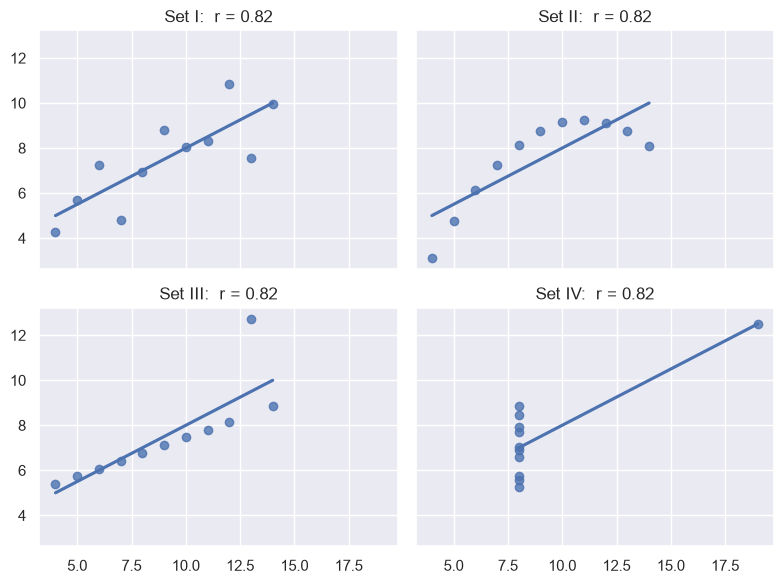

In [61]:
x_main = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = {
    "I":   (x_main, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  (x_main, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": (x_main, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  ([8] * 7 + [19] + [8] * 3,
            [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}

fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True)
for ax, (name, (x, y)) in zip(axes.ravel(), anscombe.items()):
    sns.regplot(x=x, y=y, ci=None, ax=ax)
    ax.set_title(f"Set {name}:  r = {np.corrcoef(x, y)[0, 1]:.2f}")
fig.tight_layout()

All four have the same `r` (and the same averages). Only one of them is
well described by a straight line. **Always plot the pair before you
trust the number.**

### Correlation is not causation

In our data, `phone_hours` has a weak negative correlation with `gpa`.
Does phone use lower GPA? Or do students who are struggling use their
phones more? Or does something else drive both? A correlation can't
tell you. It tells you where to look.

### Exercise 5.1
Compute:

- `r_study_gpa`: the correlation between `study_hours` and `gpa`,
  rounded to 2 decimals
- `strongest_with_gpa`: the column (other than `gpa` itself) with the
  strongest correlation with `gpa`, positive or negative (a string)

In [62]:
r_study_gpa = df["study_hours"].corr(df["gpa"]).round(2)
strongest_with_gpa = df.drop(columns="student_id").corr(numeric_only=True)["gpa"].drop("gpa").abs().idxmax()



In [63]:
assert r_study_gpa is not None and strongest_with_gpa is not None, "fill in both answers"
assert abs(r_study_gpa - round(df["study_hours"].corr(df["gpa"]), 2)) < 0.005, \
    "r_study_gpa is not the correlation of study_hours and gpa - try df['study_hours'].corr(df['gpa'])"
expected = corr["gpa"].drop("gpa").abs().idxmax()
assert strongest_with_gpa == expected, \
    "look at the gpa column of the correlation table: which value is furthest from 0?"
print("Exercise 5.1 correct.")

Exercise 5.1 correct.


### Exercise 5.2
Look at the four Anscombe plots. In which sets is a straight line (and so
the correlation) **misleading**? Store them as a list of strings, for
example `["I", "II"]`.

In [64]:
misleading_sets = ["II", "III", "IV"]


In [65]:
assert misleading_sets, "fill in misleading_sets"
assert sorted(misleading_sets) == ["II", "III", "IV"], \
    "look again: set I is a fair straight-line scatter. In the others, is the pattern a curve, or does one point decide the line?"
print("Exercise 5.2 correct.")
print("II is a curve, III has one outlier dragging the line, IV has one point that decides the whole line.")

Exercise 5.2 correct.
II is a curve, III has one outlier dragging the line, IV has one point that decides the whole line.


---
# AI checkpoint

**Pattern: check what the chart claims.**

### Step 1
Give an AI assistant this exact prompt, unmodified:

> "Using pandas and matplotlib, make a chart showing which department is
> best at GPA. The data is in data/students_eda.csv with columns
> student_id, dept, study_hours, attendance, phone_hours, gpa."

### Step 2
Paste its code below and run it.

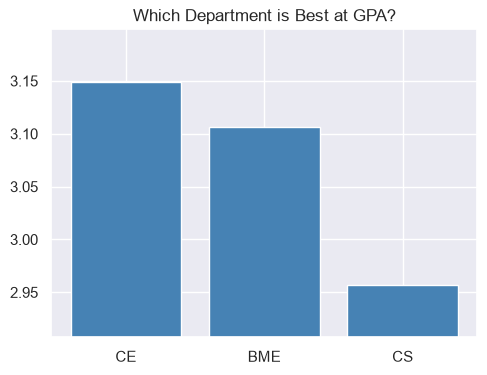

In [66]:
# Paste the AI assistant's code here and run it
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/students_eda.csv")

avg_gpa = df.groupby("dept")["gpa"].mean().sort_values(ascending=False)

plt.figure(figsize=(5.5, 4))
plt.bar(avg_gpa.index, avg_gpa.values, color="steelblue")
plt.ylim(avg_gpa.min() - 0.05, avg_gpa.max() + 0.05)
plt.title("Which Department is Best at GPA?")
plt.show()

### Step 3: answer these in your own words

**Q1. Chart choice.** Is a chart of averages the right answer to "which
department is best"? What does it leave out? (Part 3 and Part 4.)

No, A bar chart of averages hides how spread out each department's GPAs are and how many students are in each group, so it can't show whether one department is really better. A box plot and a count plot would show those.

**Q2. Honesty.** Where does the y axis start? Does the chart have axis
labels and units? (Part 1.)

The y axis doesn't start at 0, the chart also has no axis labels and no units, only a title.

**Q3. The claim.** The chart implies one department is "best". Draw the
Part 3 bar plot with its confidence lines and the box plot. Would you
stand by that claim?

No, the bars for the departments overlap a lot, so the differences in average GPA may not be real. The box plots also show the GPAs of the departments overlap heavily. I wouldn't claim one department is best from this chart.

**Q4. The prompt.** What would you add to the prompt to get a more
honest chart?

I would say how to measure the best average GPA, and ask for the y axis to start at 0, with a title, axis labels and units. I would also ask for a box plot, and for the number of students in each department.

> **The point:** the prompt said "best" without saying how to measure it
> or how sure to be. The assistant filled that gap silently, and a chart
> looks more certain than a sentence does.

---
# Going further


| Part | Resource | Why it's worth your time |
|---|---|---|
| 1 | [From Data to Viz](https://www.data-to-viz.com/) | Pick your data type and it suggests charts. Its *caveats* section shows common chart mistakes. |
| 1 | [Fundamentals of Data Visualization](https://clauswilke.com/dataviz/), Claus O. Wilke | A free online book on what makes a figure clear and honest. |
| 2 | [Matplotlib documentation](https://matplotlib.org/stable/users/index.html) | Start with the *Quick start guide*. |
| 3, 4 | [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html) | The official walkthrough of every plot type used in this lab. |
| 5 | [Anscombe's quartet](https://en.wikipedia.org/wiki/Anscombe%27s_quartet) | The story behind the four datasets in Part 5. |
| 5 | [Spurious Correlations](https://www.tylervigen.com/spurious-correlations) | Funny, real examples of correlation without causation. |

**(Optional) Try it yourself:** pick a dataset from Kaggle that you find interesting
and ask it three questions, one chart each, using the Part 1 table to
choose the chart.

---
# Before you finish

- [ ] Every self-check cell prints "correct"
- [ ] `matplotlib` and `seaborn` installed **and** recorded in `requirements.txt`
- [ ] `figures/attendance_vs_gpa.png` exists in your course folder
- [ ] AI checkpoint answered in your own words
- [ ] **Restart Kernel and Run All**: the whole notebook runs with no errors
- [ ] Committed and pushed

### The habits worth keeping

1. Pick the chart from the question, not the other way round.
2. Label everything, and start bar charts at zero.
3. Check group sizes before trusting a group average.
4. An outlier is a question, not an error.
5. Plot the pair before you trust a correlation.
6. A correlation tells you where to look, not what caused what.